# 01 — Coleta de Dados

Coleta e inspeção visual das fontes de dados do MVP:

| Fonte | Dado | Módulo |
|---|---|---|
| Yahoo Finance | Futuros arábica ICE NY (`KC=F`, cents/lb) e câmbio `BRL=X` | `src/data/market.py` |
| Banco Central (SGS) | PTAX venda (série 1) e Meta Selic (série 432) | `src/data/bcb.py` |
| CEPEA/ESALQ | Preço físico arábica e robusta (R$/saca 60 kg) — **download manual** em `data/external/` | `src/data/cepea.py` |

> O CEPEA bloqueia downloads automatizados (HTTP 403). As series foram baixadas manualmente de
> https://www.cepea.esalq.usp.br/br/indicador/cafe.aspx no padrao
> `data/external/cepea-consulta-<freq>-<produto>-<ano>.xls` (a frequencia diaria vem dividida em
> dois arquivos por produto, por limite do site). Apesar do 1986 no nome, o indicador arabica
> inicia em set/1996 e o robusta em nov/2001.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# permite importar src/ a partir da pasta notebooks/
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
RAW = ROOT / 'data' / 'raw'

plt.rcParams['figure.figsize'] = (12, 4)

## 1. Executar a coleta

Roda todas as fontes e salva os brutos em `data/raw/`. Pode ser re-executada a qualquer momento para atualizar os dados.

In [2]:
from src.data.collect import main as collect_all

collect_all(start='2010-01-01')

1/3 Yahoo Finance (KC=F, BRL=X)...
    4343 linhas -> market_yahoo.csv
2/3 Banco Central (PTAX, Selic)...
    6088 linhas -> macro_bcb.csv
3/3 CEPEA (arábica e robusta, arquivos manuais)...
    7470 linhas -> cepea_cafe.csv
Coleta concluída.


## 2. Futuros de café (ICE NY) e câmbio — Yahoo Finance

In [3]:
market = pd.read_csv(RAW / 'market_yahoo.csv', index_col='date', parse_dates=True)
display(market.tail())
market.describe()

,ice_arabica_cents_lb,usd_brl_yahoo
date,,
2026-08-26,357.600006,5.1464
2026-08-27,341.899994,5.1474
2026-08-28,345.850006,5.1611
2026-08-31,343.899994,5.1912
2026-09-01,308.350006,NaN


,ice_arabica_cents_lb,usd_brl_yahoo
count,4190.000000,4335.000000
mean,179.223461,3.754934
std,73.932574,1.410889
min,86.650002,1.533700
25%,123.462498,2.275150
50%,157.500000,3.766500
75%,218.575005,5.164500
max,438.899994,6.300000


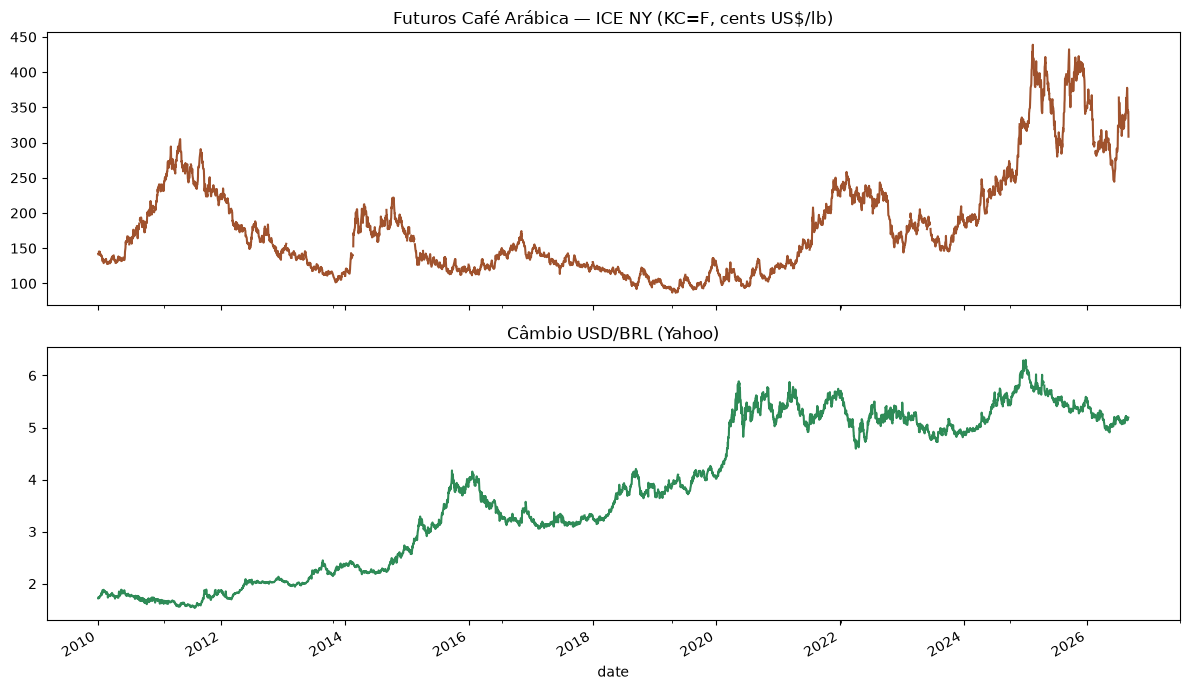

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
market['ice_arabica_cents_lb'].plot(ax=axes[0], color='sienna', title='Futuros Café Arábica — ICE NY (KC=F, cents US$/lb)')
market['usd_brl_yahoo'].plot(ax=axes[1], color='seagreen', title='Câmbio USD/BRL (Yahoo)')
plt.tight_layout()

## 3. Macro oficial — Banco Central (PTAX e Selic)

,ptax_venda,selic_meta
date,,
2026-08-28,5.2005,14.0
2026-08-29,NaN,14.0
2026-08-30,NaN,14.0
2026-08-31,5.1816,14.0
2026-09-01,5.1570,14.0


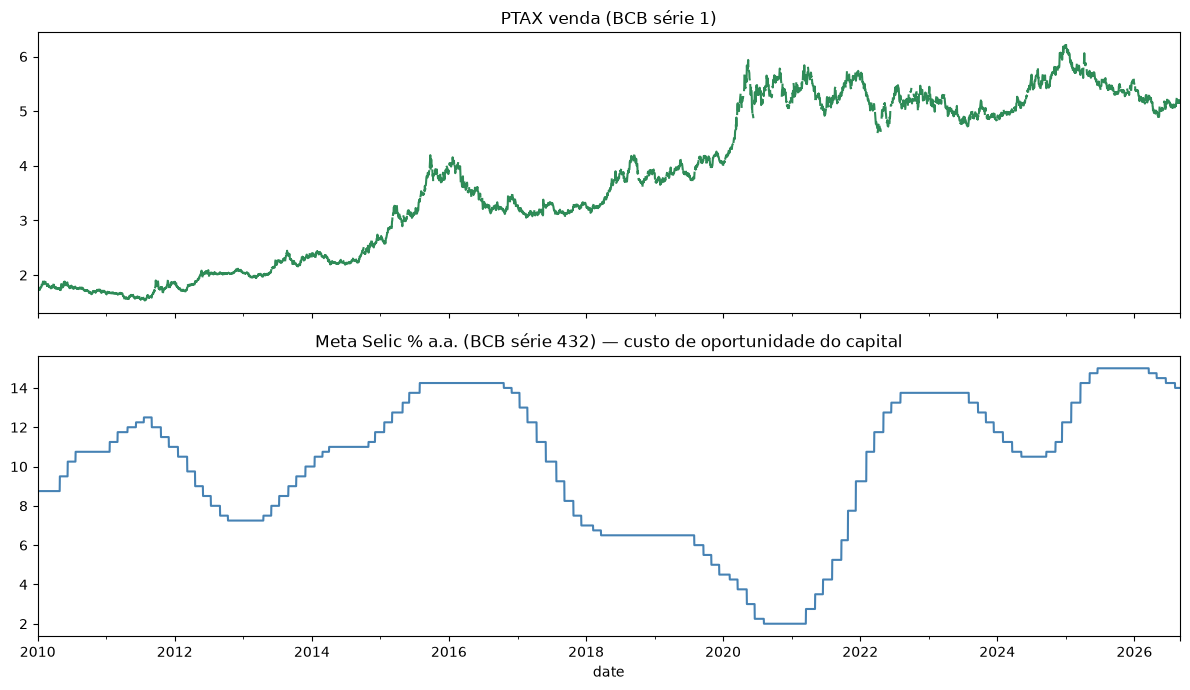

In [5]:
macro = pd.read_csv(RAW / 'macro_bcb.csv', index_col='date', parse_dates=True)
display(macro.tail())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
macro['ptax_venda'].plot(ax=axes[0], color='seagreen', title='PTAX venda (BCB série 1)')
macro['selic_meta'].plot(ax=axes[1], color='steelblue', title='Meta Selic % a.a. (BCB série 432) — custo de oportunidade do capital')
plt.tight_layout()

## 4. Preço físico CEPEA/ESALQ (arábica e robusta)

Este é o preço que o produtor efetivamente recebe (mercado físico, R$/saca de 60 kg) — a variável-alvo do sistema. Requer os XLS baixados manualmente em `data/external/`.

,cepea_arabica_brl_sc,cepea_arabica_usd_sc,cepea_robusta_brl_sc,cepea_robusta_usd_sc
date,,,,
2026-08-25,1821.25,353.85,1048.71,203.75
2026-08-26,1800.79,349.40,1036.13,201.03
2026-08-27,1742.74,337.35,1021.90,197.81
2026-08-28,1728.61,332.30,1027.55,197.53
2026-08-31,1748.44,337.41,1022.13,197.25


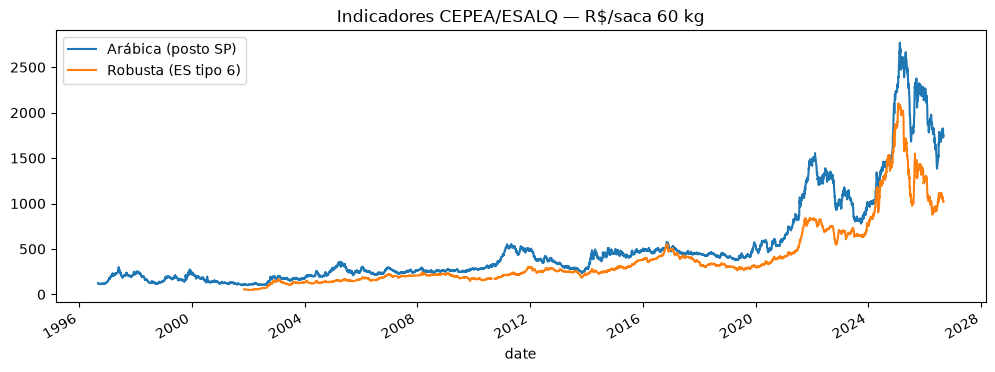

In [6]:
cepea_csv = RAW / 'cepea_cafe.csv'
if cepea_csv.exists():
    cepea = pd.read_csv(cepea_csv, index_col='date', parse_dates=True)
    display(cepea.tail())
    ax = cepea.filter(like='brl_sc').plot(title='Indicadores CEPEA/ESALQ — R$/saca 60 kg')
    ax.legend(['Arábica (posto SP)', 'Robusta (ES tipo 6)'])
else:
    print('Arquivos do CEPEA ainda não baixados — ver instruções no topo do notebook.')

## 5. Sanidade: cobertura temporal e valores faltantes

Checagem rápida antes de partir para o alinhamento temporal e a engenharia de features (notebook 02).

In [7]:
for name, df in {'market_yahoo': market, 'macro_bcb': macro}.items():
    print(f'{name}: {df.index.min().date()} a {df.index.max().date()} | {len(df)} linhas | NaNs: {df.isna().sum().sum()}')

# cruzamento arábica futuro x físico será feito no notebook 02, após alinhamento

market_yahoo: 2010-01-04 a 2026-09-01 | 4343 linhas | NaNs: 161
macro_bcb: 2010-01-01 a 2026-09-01 | 6088 linhas | NaNs: 1902
